**Instructions:**

- Do not write your name on the assignment. Be careful about any warnings that might display some file path with your name included.
- Receiving help from classmates and/or ideas from Generative AI is allowed. **However, you must submit your own original work.**
- For questions that require coding, you need to write the relevant code and display its output. Your output should either be the direct answer to the question or clearly display the answer in it.
- For questions that require a written answer (sometimes along with the code), you need to put your answer in a Markdown cell. Writing the answer as a comment or as a print line is not acceptable.
- You need to render this file as HTML using Quarto and submit the HTML file. **Please note that this is a requirement and not optional.** A submission cannot be graded until it is properly rendered.

Proper formatting: **5 points**
- Quarto rendering **(2 points)** (If the file is rendered wrong, the correct version needs to be submitted first to be eligible for grading; 2 points will be deducted afterwards.)
- No unnecessary/redundant/commented-out code chunk, text or output. **(2 points)**
- Written answers in Markdown cells, not added as a comment or a print line. **(1 points)**

Import all the libraries and tools you need below.

In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from imblearn.over_sampling import RandomOverSampler

## 1) Hinge Cost for SVM Regression (15 points)

In this question, you will derive the Hinge cost function for a Support Vector Regressor (SVR). The following instructions should be helpful:

- Start either by assuming there is one support vector whose distance to the regression fit is $a$ or there are two support vectors who are equidistant to the regression fit with a distance of $a$ on each side.
- Using the hyperplane(s) parallel to the fit and passing through the support vector(s), express what you need to maximize and minimize.
- Write the hard margin optimization problem. Indicate why it is not feasible.
- Write the soft margin optimization problem, which should be the cost function. Note that $a$ will be a part of it.

Please note that the math required for this question can be found in many easily available resources, including generative AI outputs, machine learning textbooks, data science blogs, etc. Each resource uses its own notation and mathematical tools. **To accurately assess your understanding of how SVMs are formulated, you are required to strictly follow the notation and math covered in the SVM lectures for any credit from this question.**

For a Support Vector Machine regression, instead of trying to maximize the margin between two classes, we want to find a regression line that keeps the observations within a margin of size $a$.

The regression fit is:

$$
\hat y = \mathbf{x}^T\mathbf{w}
$$

and the two lines passing through the support vectors are:

$$
y = \mathbf{x}^T\mathbf{w}+a
$$

$$
y = \mathbf{x}^T\mathbf{w}-a
$$

The total width of the margin is $2a$. We want the observations to be close to the regression fit, so we want to minimize $a$.

For the hard margin case, no observations can be outside these two lines, which can be written as:

$$
\min_{\mathbf{w},a} \quad a+\lambda\|\mathbf{w}\|^2
$$

subject to:

$$
\max(0,|y^{(i)}-\mathbf{x}^{(i)T}\mathbf{w}|-a)=0
$$

for $i=1,\ldots,M$, with $a\geq0$.

But this is too restrictive since we might have observations outside the margin, especially if $a$ is small.

Similar to classification, we use a hinge cost to penalize those observations. If an observation is inside the margin, the cost is 0. Otherwise, the cost increases depending on how far outside it is.

So the soft margin cost function becomes:

$$
\boxed{
H(\mathbf{w},a)=
\sum_{i=1}^{M}
\max(0,|y^{(i)}-\mathbf{x}^{(i)T}\mathbf{w}|-a)
+\lambda\|\mathbf{w}\|^2+a
}
$$

The first term penalizes observations outside the margin, the second regularizes the weights, and the last term keeps the margin from becoming way too large.

---

**AI Usage Disclosure**

I asked ChatGPT to help me derive the hinge cost function for SVM regression. My prompt was:

*"Using the SVM lecture slides and notes from my STAT 362 class, derive the hinge cost function for SVM regression, assuming that a is a variable rather than a fixed hyperparameter. Use the same notation and approach as the lectures, just give me the math formulas."*

+ I attached Support_Vector_Machines.pdf and SVM_Notes.html

I used the formulas it provided to work through the derivation and wrote explanation myself.

## 2) SVM Classification (26 points)

In this question, you will use the **magic_telescope.csv** file. This file contains simulated measurements taken from [MAGIC telescope](https://en.wikipedia.org/wiki/MAGIC_(telescope)), which is used to detect gamma rays. 

- Each observation in the dataset is a detection of an electromagnetic shower.
- The last variable shows whether the shower is caused by a gamma ray (g) or by cosmic rays in the upper atmosphere, which is called a hadronic shower (h). This should be the response (target) variable.
- All the other variables are astrophysical measurements of the detected shower and they should be the features.

### a)

- Read the data. Use `header=None` because there are not any column names in the csv file.
- Map the **g** and **h** class labels into 0 and 1, respectively.
- Split the data into **stratified** training and test sets with a 70%-30% ratio. Use `random_state=2` for reproducible results. Scale the training and test data.

**(3 points)**

In [15]:
df = pd.read_csv("magic_telescope.csv", header=None)

df[10] = df[10].map({"g":0, "h":1})

X = df.drop(columns=[10])
y = df[10]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=2)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### b)

Using the preprocessed data, tune a Support Vector Classifier (SVC). The type of kernel and the hyperparameter grid values are entirely up to you. If you think it is necessary, you are allowed to tune the decision threshold as well. 

Your model should meet the following criteria:
- A 5-fold cross-validation (CV) accuracy of at least 87%
- A 5-fold cross-validation (CV) recall of at least 71%

**Every object that takes a `random_state` in your solution must have `random_state=2`.** This includes the model object, the randomized grid search (if you use it) and any KFold/StratifiedKFold object (or their repeated versions).

**Print the CV accuracy and the CV recall of the tuned model.**

**Hint:** Keep in mind that you are using an SVM, which is not very scalable to increasing data size. Practical approaches like keeping small grids and using random searches should be useful. Also keep in mind that different kernels have different hyperparameters.

**(20 points)**

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)

param_grid = {
    "C": [1, 5, 10, 100],
    "gamma": ["scale"],
    "kernel": ["rbf"]
}

grid = GridSearchCV(
    SVC(random_state=2),
    param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

best_svc = grid.best_estimator_

scores = cross_validate(
    best_svc,
    X_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "recall"],
    n_jobs=-1
)

print("Best parameters:", grid.best_params_)
print("CV Accuracy:", scores["test_accuracy"].mean())
print("CV Recall:", scores["test_recall"].mean())

Best parameters: {'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}
CV Accuracy: 0.8728402661849375
CV Recall: 0.7281006850377182


### c)

Print the test accuracy and the test recall of the tuned SVC. Do the CV results generalize well to the test data? **(3 points)**

In [17]:
y_pred = best_svc.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_recall = recall_score(y_test, y_pred)

print(f"Test Accuracy: {test_accuracy:.2%}")
print(f"Test Recall: {test_recall:.2%}")

Test Accuracy: 87.35%
Test Recall: 73.18%


Yeah, the CV results generalize well to the test data, it even has a higher Acurracy and Recall

## 3) Linear Multi-Class Classification (39 points)

In this question, you will extend your custom Logistic Regression model from the previous homework assignment to a multi-class setting. You will use a One-vs-Rest (OvR) approach.

### a)

Read the data from the **phone_price.csv** file. Each observation is a phone and the variables are its specifications.

The `price_range` variable represents the price level of the phone, 0 being the cheapest and 3 being the most expensive. It is the response (target) variable for the classification task. All variables other than `price_range` should be the features. 

Print how many observations there are for each class to find out if the classes are balanced or not.

**(2 points)**

In [18]:
df = pd.read_csv("phone_price.csv")

X = df.drop(columns="price_range")
y = df["price_range"]

print(y.value_counts())

price_range
1    500
2    500
3    500
0    500
Name: count, dtype: int64


### b)

Split the data into **stratified** training and test sets with a 80%-20% ratio. Use `random_state=2` for reproducible results. Scale the training and test data. **(1 point)**

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=2)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### c)

In Part a, you should see a balance between all classes. Why then is stratification important while creating training and test sets, **in particular with more than two classes**? **(4 points)**

Even if the dataset is balanced, the random split could make the training and test sets unbalanced. Stratification makes sure that each class keeps the same proportion in both sets. When having more that two classes, this is even more important because some classes can be under or overrepresented, which will affect how the model learns and how it evaluates.

### d)

Copy your custom Logistic Regression code from the previous homework assignment. Note that you should have six functions in total. **(0 points)**

In [20]:
#| echo: false

# The YAML setting above will hide this cell in the HTML file for visual purposes. 
# Put all your code for Part d here. 

def initialize(dim):
    return np.random.rand(dim + 1)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def predict(model_params, X_test, threshold):
    X = np.column_stack((np.ones(len(X_test)), X_test))
    probabilities = sigmoid(X @ model_params)
    return (probabilities >= threshold).astype(int)

def calc_cost_gradient(model_params, X_train, y_train):
    X = np.column_stack((np.ones(len(X_train)), X_train))
    y_pred = sigmoid(X @ model_params)

    cost = -np.mean(y_train * np.log(y_pred) + (1 - y_train) * np.log(1 - y_pred))
    gradient = (X.T @ (y_pred - y_train)) / len(y_train)

    return cost, gradient

def GradientDescent(model_params, X_train, y_train, lr, iters, tol):
    costs = []

    for i in range(iters):
        cost, gradient = calc_cost_gradient(model_params, X_train, y_train)
        costs.append(cost)

        new_params = model_params - lr * gradient

        if np.linalg.norm(new_params - model_params, 2) < tol:
            model_params = new_params
            break

        model_params = new_params

    else:
        print("Warning: Algorithm may not have converged.")

    final_cost, _ = calc_cost_gradient(model_params, X_train, y_train)

    print("Final BCE:", final_cost)

    plt.plot(costs)
    plt.show()
    
    return model_params


def logistic_regression(X_train, y_train, X_test, y_test, lr, iters, tol, threshold = 0.5):
    model_params = initialize(X_train.shape[1])
    model_params = GradientDescent(model_params, X_train, y_train, lr, iters, tol)
    y_pred = predict(model_params, X_test, threshold)
    print("Test Accuracy:", accuracy_score(y_test, y_pred))
    print("Test Recall:", recall_score(y_test, y_pred))
    return model_params


### e)

Define a function called `logistic_regression_mc`. This function will be the multi-class Logistic Regression model with the OvR approach. It should take the same inputs as the `logistic_regression` function and return the parameters of all the OvR models together in a data structure of your choice.

The following steps should be helpful for your implementation:
- Loop through the class values. **Do not hard code, use the inputs to obtain the unique class values in the right order.** For each class value:
    - You need to update your response (target) variables into a binary (OvR) setting. **Be careful about overwriting here!**
    - Call the `logistic_regression` function with the OvR classes and obtain the optimum parameters.
    - Store the optimum parameters.
    - Calculate the Class 1 probability (in the OvR setting) for test data and store them. 
- After the loop, using the (OvR) Class 1 probabilities from all classifiers, predict the class (in the multi-class setting).
- Print the accuracy, **multi-class** confusion matrix and the `classification_report` for the test data.
- Return the data structure with optimum parameters (from all classifiers).

**(20 points)**

In [21]:

def logistic_regression_mc(X_train, y_train, X_test, y_test, lr, iters, tol, threshold=0.5):
    classes = np.sort(np.unique(y_train))
    model_params = {}
    probabilities = []

    for c in classes:
        y_train_binary = (np.asarray(y_train) == c).astype(int)
        y_test_binary = (np.asarray(y_test) == c).astype(int)

        params = logistic_regression(X_train, y_train_binary, X_test, y_test_binary, lr, iters, tol, threshold)

        model_params[c] = params

        X = np.column_stack((np.ones(len(X_test)), X_test))
        probabilities.append(sigmoid(X @ params))

    probabilities = np.column_stack(probabilities)
    y_pred = classes[np.argmax(probabilities, axis=1)]

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred, labels=classes))
    print("Classification Report:")
    print(classification_report(y_test, y_pred, labels=classes))

    return model_params

### f)

Call the `logistic_regression_mc` function with the preprocessed data. Keep the threshold at 0.5. Experiment with the tolerance, the learning rate and the number of iterations. You should see four plots with converging costs and the printed multi-class test results. 

It is fine to keep the test results of the binary/OvR models printed, but disregard those numbers. It is also fine to see the warning message for some of the binary/OvR models.

**Your macro precision, macro recall and overall accuracy should all be above 80% for the test data to receive full credit from this part.**

**(7 points)**

Final BCE: 0.031426239025442115


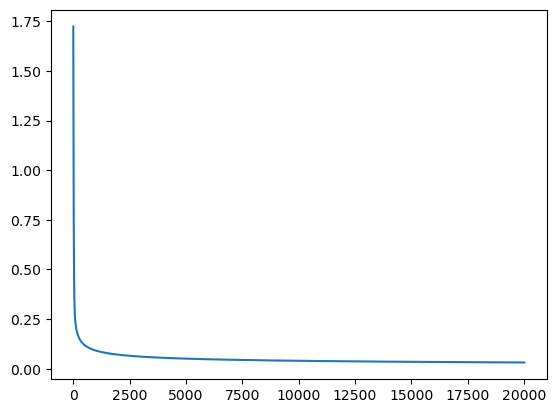

Test Accuracy: 0.985
Test Recall: 0.99
Final BCE: 0.5269386429767096


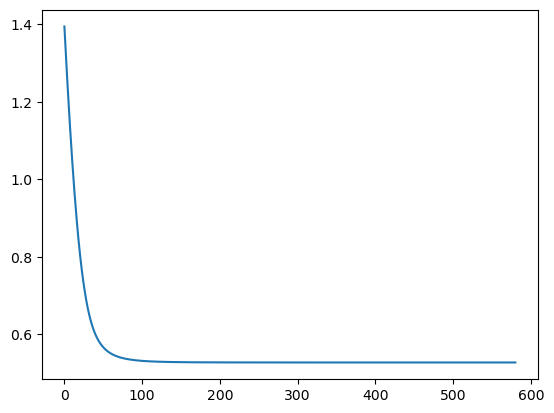

Test Accuracy: 0.735
Test Recall: 0.01
Final BCE: 0.5244250033745748


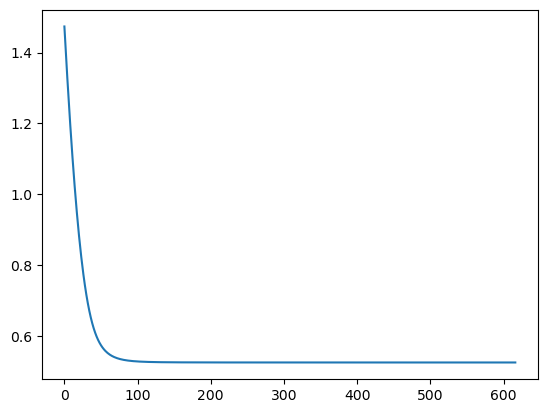

Test Accuracy: 0.715
Test Recall: 0.0


In [ ]:
mc_params = logistic_regression_mc(
    X_train,
    y_train,
    X_test,
    y_test,
    lr=0.15,
    iters=20000,
    tol=0.00001,
    threshold=0.5
)

### g)

Which classes were easier to predict for the model? Which classes have more misclassifications? What real-life intuition do the results give you in terms of the price ranges of the phones? **(4 points)**

Classes 0 and 3 were easier to predict, classes 1 and 2 had way more misclassifications. It actually makes sense because cheap and expensive phones have more disctintions, while phones in the middle price ranges are more similar in terms of their characteristics, so the model does can not distinguish as well as it does with class 0 and class 3.

### h)

How many binary models would you have to call in the `logistic_regression_mc` function, if you used the One-vs-One (OvO) approach instead of OvR? **(1 point)**

6

## 4) Non-linear Multi-Class Classification (15 points)

### a)

If a K-Nearest Neighbors (KNN) classifier is used for a multi-class task, it becomes more probable to encounter the problem of having ties among the K neighbors. For example, in a binary task for K=5, one of the two classes is guaranteed to have a majority, but for a three-class task, two classes can each have 2 neighbors, with the third class having 1 neighbor. This problem gets more severe as the number of classes increase.

Assuming you want to stick to a KNN classifier, propose one solution that would be a fix to this problem. If you do some research for this, **cite your sources**.

**(3 points)**

One way to fix this would be to use distance weighted KNN. Instead of giving every neighbor the same vote, the ones that are closer count more. So even if two classes have the same number of neighbors, the one with closer neighbors would get more weight and win. This wouldn't fully eliminate ties, but it would make them less likely.

Source: https://scikit-learn.org/stable/modules/neighbors.html

For the remainder of this question, you will try to improve the multi-class classification performance of the best model from Exercise Set 5. Remember that the main issue in the assignment was the class imbalance between multiple classes.

While the following parts do not take much coding or conceptual understanding, their purpose is to provide some good practical insight. While working on a Machine Learning task in Python, you may reach the end of your options in scikit-learn to improve your model. In this case, exploring a new library that is built on scikit-learn for a specific purpose would be necessary.

To improve the classifier performance on imbalanced datasets, [imbalanced-learn](https://imbalanced-learn.org/stable/index.html) library is developed.

### b)

Read and preprocess the data from **cirrhosis_outcomes.csv**. You should have this part ready in Exercise Set 5. **(0 points)**

**Note:** Since the model in this question will be tree-based, scaling is not mandatory and should not change the result.

In [ ]:
df = pd.read_csv("cirrhosis_outcomes.csv", index_col=0)

df["Status"] = df["Status"].map({
    "C": 0,
    "D": 1,
    "CL": 2
})

X = df.drop(columns=["Status"])
y = df["Status"]

X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### c)

Create the tuned model that returned the best cross-validation macro f1-score in Exercise Set 5. You can directly set the tuned hyperparameter values in the model object and leave everything else default. Keep `random_state=1` for comparison purposes. **(2 points)**

In [ ]:
model = XGBClassifier(
    learning_rate=0.1,
    max_depth=4,
    n_estimators=300,
    random_state=1
)

### d)

Before training the model, you need to transform the training data. Note that to overcome class imbalance issues, your options are oversampling, which is increasing the size of the smaller class(es), undersampling, which is decreasing the size of the larger class(es) or a combination of both.

To explore these options, you will refer to the documentation website of imbalanced-learn (link given in the text above Part b).

- First, you need to install the library, as it is not in Anaconda by default. Follow the Getting Started page for this.
- When you start to explore a brand-new library, it might be difficult to know where to start among the many options in it. Refer to the User Guide. User guides usually have the simplest (and most understandable) options at the beginning.

Resample the **training** data with a sampler of your choice and train the model with the resampled data. Print the `classification_report` and the **micro** recall for the test data. **The requirement for this question is to get the test macro recall to (at least) 65% with a test micro recall of (at least) 70%.**

**Note:** 
- The test data in this question works as validation data. This is only to demonstrate how the resampling improves the results. In a real-life setting, **never** use the test data to improve the model; it should only be used at the end for the final evaluation.
- Do not resample the test data.

**(10 points)**

In [ ]:
ros = RandomOverSampler(random_state=1)

X_train_resampled, y_train_resampled = ros.fit_resample(
    X_train, y_train
)

model.fit(X_train_resampled, y_train_resampled)

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))
print("Macro Recall:", recall_score(y_test, y_pred, average="macro"))
print("Micro Recall:", recall_score(y_test, y_pred, average="micro"))


              precision    recall  f1-score   support

           0       0.87      0.85      0.86       993
           1       0.77      0.78      0.77       533
           2       0.27      0.35      0.30        55

    accuracy                           0.81      1581
   macro avg       0.63      0.66      0.64      1581
weighted avg       0.81      0.81      0.81      1581

Macro Recall: 0.6576695919706752
Micro Recall: 0.8077166350411132
